# Exercise: How many nodes?

Can a neural net tell **EDM** from **rap**? Do more nodes help?

Let's revisit the Spotify data from the lecture 13 exercise and compare logistic regression, a random forest, and neural nets with 2, 10, and 50 hidden nodes.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──


✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 


── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Dig deeper into tidy modeling with R at https://www.tmwr.org


## The data

Each row is one song. `genre` is `rap` or `edm`. The predictors are `danceability` and `tempo`.

In [2]:
songs <- read.csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-01-21/spotify_songs.csv')

songs <- songs |>
    filter(playlist_genre %in% c('edm', 'rap')) |>
    distinct(track_id, .keep_all = TRUE) |>
    mutate(genre = factor(playlist_genre, levels = c('rap', 'edm'))) |>
    select(track_name, track_artist, genre, danceability, tempo)

songs |> count(genre)

  genre n   
1 rap   5486
2 edm   5437

## Setup for the models

Run these cells. Do not change them.

- Split the songs in half: `train` and `test`.
- `train_small` has only 100 songs from `train`.
- `fit_nn()` fits a neural net with `h` hidden nodes. It normalizes the predictors first.
- `accuracy_of()` finds the share of songs a model gets right.

In [3]:
set.seed(512)
split <- initial_split(songs, prop = 0.5, strata = genre)
train <- training(split)
test  <- testing(split)

set.seed(3)
train_small <- train |> slice_sample(n = 100)

In [4]:
rec <- recipe(genre ~ danceability + tempo, data = songs) |>
    step_normalize(all_predictors())

fit_nn <- function(h, data) {
    set.seed(1)
    workflow() |>
        add_recipe(rec) |>
        add_model(
            mlp(hidden_units = h, epochs = 1000, penalty = 0) |>
                set_mode('classification') |>
                set_engine('nnet', MaxNWts = 5000)
        ) |>
        fit(data = data)
}

accuracy_of <- function(fit, data) {
    pred <- predict(fit, new_data = data, type = 'class')$.pred_class
    mean(pred == data$genre)
}

## 1. Small data: 100 songs

`compare_models()` fits five models: logistic regression, a random forest, and neural nets with 2, 10, and 50 hidden nodes. It returns two accuracies for each model:

- `train_accuracy`: on the songs used to fit the model.
- `test_accuracy`: on the `test` songs, which the model has not seen.

Run the cell. It uses only `train_small`, which has 100 songs.

In [5]:
compare_models <- function(train_data) {
    set.seed(512)
    fits <- list(
        logistic = logistic_reg() |> fit(genre ~ danceability + tempo, data = train_data),
        forest   = rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger') |>
                       fit(genre ~ danceability + tempo, data = train_data),
        `nn 2`   = fit_nn(2, train_data),
        `nn 10`  = fit_nn(10, train_data),
        `nn 50`  = fit_nn(50, train_data)
    )

    tibble(
        model = names(fits),
        train_accuracy = map_dbl(fits, accuracy_of, data = train_data),
        test_accuracy  = map_dbl(fits, accuracy_of, data = test)
    )
}

results_small = compare_models(train_small)

results_small

         model    train_accuracy test_accuracy
logistic logistic 0.57           0.6054559    
forest   forest   0.91           0.7995240    
nn 2     nn 2     0.86           0.8061150    
nn 10    nn 10    0.92           0.7724277    
nn 50    nn 50    0.99           0.7158550    

**Check:** `nn 50` should be right for about 0.99 of the training songs.

- **Training:** `nn 50` is best, at about 0.99 accuracy.
- **Test:** `nn 2` is best at about 0.81, while `nn 10` and `nn 50` fall to about 0.77 and 0.72.
- Test accuracy falls as the net gains 10 and especially 50 nodes, showing clear overfitting on the small training set.
- A net with 50 hidden nodes learns 201 numbers, but we gave it only 100 songs.


## 2. Chart the output

Pick a visualization for the output and make the chart below. Write the code by hand or prompt it with `OpenCode`.

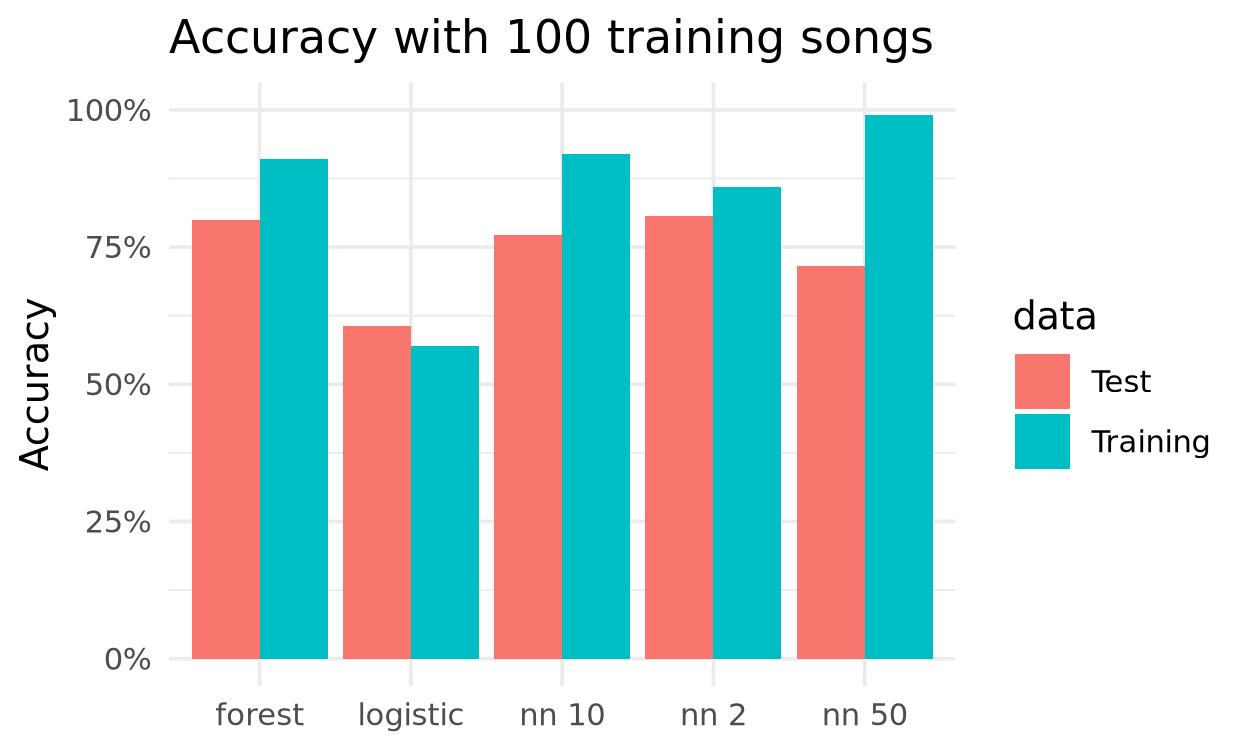

In [6]:
results_small |>
    pivot_longer(c(train_accuracy, test_accuracy), names_to = 'data', values_to = 'accuracy') |>
    mutate(data = recode(data,
        train_accuracy = 'Training',
        test_accuracy = 'Test')) |>
    ggplot(aes(x = model, y = accuracy, fill = data)) +
        geom_col(position = 'dodge') +
        scale_y_continuous(limits = c(0, 1), labels = scales::percent) +
        labs(title = 'Accuracy with 100 training songs', x = NULL, y = 'Accuracy') +
        theme_minimal()


## 3. More data

Run `compare_models()` again, with all of `train` (about 5,500 songs).

In [7]:
results_all <- compare_models(train)

results_all


         model    train_accuracy test_accuracy
logistic logistic 0.6033693      0.6023435    
forest   forest   0.9366416      0.8196631    
nn 2     nn 2     0.8090093      0.8149030    
nn 10    nn 10    0.8170665      0.8218601    
nn 50    nn 50    0.8331807      0.8147199    

**Check:** the nets should now be close to the forest, at about 0.82 on the test songs.

- With more data, `nn 50` is no longer much worse than `nn 2`; additional nodes help or at least do not create as much overfitting now.
- Logistic regression stays near 0.60 because it draws only a straight boundary and cannot capture the nonlinear EDM tempo stripe.


## 4. Plot the results when using all the data

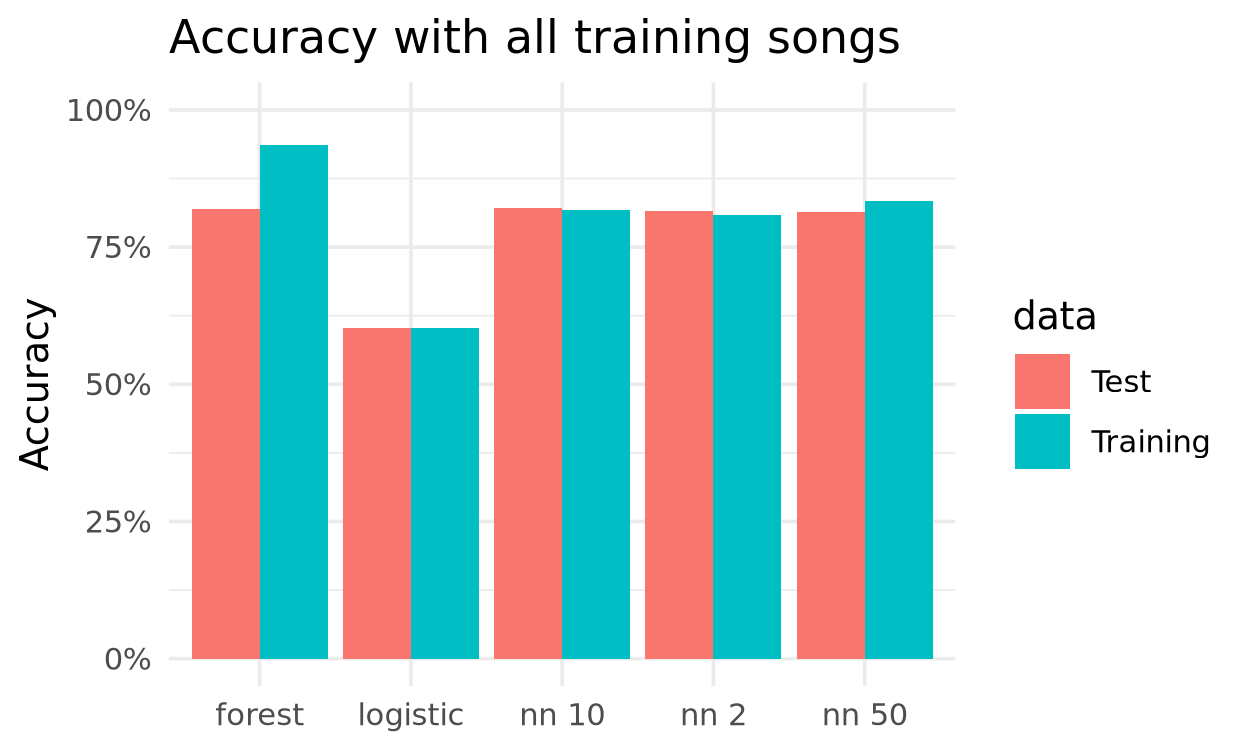

In [8]:
results_all |>
    pivot_longer(c(train_accuracy, test_accuracy), names_to = 'data', values_to = 'accuracy') |>
    mutate(data = recode(data,
        train_accuracy = 'Training',
        test_accuracy = 'Test')) |>
    ggplot(aes(x = model, y = accuracy, fill = data)) +
        geom_col(position = 'dodge') +
        scale_y_continuous(limits = c(0, 1), labels = scales::percent) +
        labs(title = 'Accuracy with all training songs', x = NULL, y = 'Accuracy') +
        theme_minimal()


## 5. Which model?

You must pick one model for a new playlist with **100 labeled songs**. Which do you pick?

*Your answer:* I would pick `nn 10`, which has the highest test accuracy in `results_all` (about 0.822). It is slightly ahead of the forest (about 0.820), while being close to `nn 2` and `nn 50`. It gives nonlinear flexibility without the overfitting seen in the 100-song experiment. I would not pick logistic regression.
